In [67]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("01 house.csv", usecols = ['GarageQual', 'FireplaceQu', 'SalePrice'])

In [3]:
df.sample(10)

,FireplaceQu,GarageQual,SalePrice
785,Gd,TA,161500
170,NaN,TA,128500
392,NaN,TA,106500
866,Gd,TA,248900
1001,NaN,Fa,86000
216,NaN,TA,210000
893,Gd,TA,165000
341,NaN,TA,82000
568,Gd,Gd,316600
130,Gd,TA,226000


In [4]:
df.isnull().sum()

FireplaceQu    690
GarageQual      81
SalePrice        0
dtype: int64

In [5]:
(df.isnull().mean())* 100

FireplaceQu    47.260274
GarageQual      5.547945
SalePrice       0.000000
dtype: float64

In [6]:
df['Garage_imputed'] = df['GarageQual']
df['Fire_imputed'] = df['FireplaceQu']

In [7]:
# Train/ test split

x = df    # We included 'SalePrice' column bcz it will help us in ploting chart.
y = df.SalePrice

In [8]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2)

In [9]:
x_train.sample(5)

,FireplaceQu,GarageQual,SalePrice,Garage_imputed,Fire_imputed
667,Fa,TA,193500,TA,Fa
256,NaN,TA,207500,TA,NaN
1233,NaN,TA,142000,TA,NaN
271,TA,TA,241500,TA,TA
844,Gd,TA,153900,TA,Gd


In [16]:
x_train['Garage_imputed'][x_train['Garage_imputed'].isnull()] = x_train['Garage_imputed'].dropna().sample(x_train['Garage_imputed'].isnull().sum()).values
x_test['Garage_imputed'][x_test['Garage_imputed'].isnull()] = x_test['Garage_imputed'].dropna().sample(x_test.Garage_imputed.isnull().sum()).values

# Filling missing values on Fire
x_train['Fire_imputed'][x_train['Fire_imputed'].isnull()] = x_train['Fire_imputed'].dropna().sample(x_train.Fire_imputed.isnull().sum()).values
x_test['Fire_imputed'][x_test['Fire_imputed'].isnull()] = x_test['Fire_imputed'].dropna().sample(x_test.Fire_imputed.isnull().sum(), replace = True).values


C:\Users\jugal\AppData\Local\Temp\ipykernel_12380\1092183262.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  x_train['Garage_imputed'][x_train['Garage_imputed'].isnull()] = x_train['Garage_imputed'].dropna().sample(x_train['Garage_imputed'].isnull().sum()).values
C:\Users\jugal\AppData\Local\Temp\ipykernel_12380\1092183262.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  x_test['Garage_imputed'][x_test['Garage_imputed'].isnull()] = x_test['Garage_imputed'].dropna().sample(x_test.Garage_imputed.isnull().sum()).values
C:\Users\jugal\AppData\Local\Temp\ipykernel_12380\1092183262.py:5: SettingWithCopyWarning: 
A val

In [17]:
print(x_train.isnull().sum())

FireplaceQu       554
GarageQual         64
SalePrice           0
Garage_imputed      0
Fire_imputed        0
dtype: int64


In [18]:
print(x_test.isnull().sum())

FireplaceQu       136
GarageQual         17
SalePrice           0
Garage_imputed      0
Fire_imputed        0
dtype: int64


In [20]:
x_train['Garage_imputed'].value_counts()/len(x_train['Garage_imputed'])


TA    0.943493
Fa    0.041952
Gd    0.010274
Po    0.002568
Ex    0.001712
Name: Garage_imputed, dtype: float64

In [35]:
x_train['GarageQual'].value_counts()/len(x_train['GarageQual'].dropna())

TA    0.945652
Fa    0.038949
Gd    0.010870
Po    0.002717
Ex    0.001812
Name: GarageQual, dtype: float64

In [45]:
x_train['Garage_imputed'].value_counts()/len(x_train['Garage_imputed'])


TA    0.943493
Fa    0.041952
Gd    0.010274
Po    0.002568
Ex    0.001712
Name: Garage_imputed, dtype: float64

In [59]:
temp = pd.concat(
    [
        x_train.GarageQual.value_counts() / len(x_train.GarageQual.dropna()),
        x_train['Garage_imputed'].value_counts() / len(x_train['Garage_imputed'])
    ],
    axis = 1
)

temp.columns = ['Original_garage', 'Garage_imputed']

In [60]:
temp

,Original_garage,Garage_imputed
TA,0.945652,0.943493
Fa,0.038949,0.041952
Gd,0.010870,0.010274
Po,0.002717,0.002568
Ex,0.001812,0.001712


In [65]:
temp = pd.concat(
        [
            x_train['FireplaceQu'].value_counts() / len(x_train['FireplaceQu'].dropna()),
            x_train['Fire_imputed'].value_counts() / len(x_train['Fire_imputed'])
        ],
        axis=1)

temp.columns = ['Original_fire', 'Fire_imputed']

temp

,Original_fire,Fire_imputed
Gd,0.485342,0.491438
TA,0.405537,0.400685
Fa,0.047231,0.047945
Ex,0.032573,0.031678
Po,0.029316,0.028253


C:\Users\jugal\AppData\Local\Temp\ipykernel_12380\72100974.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train[x_train['FireplaceQu'] == category]['SalePrice'],hist=False,label=category)
C:\Users\jugal\AppData\Local\Temp\ipykernel_12380\72100974.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad637

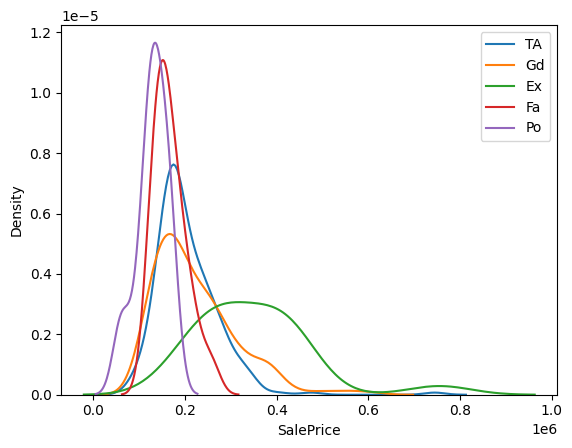

In [69]:
for category in x_train['FireplaceQu'].dropna().unique():
    sns.distplot(x_train[x_train['FireplaceQu'] == category]['SalePrice'],hist=False,label=category)

plt.legend()
plt.show()